# Modelos lineales con Bambi

Vamos a escribir las cuatro estructuras de la notebook anterior con Bambi, obtener predicciones y comparar los modelos. Usamos los mismos datos y los _priors_ automáticos de Bambi, que se muestran al crear cada modelo.

In [1]:
import arviz as az
import bambi as bmb
import matplotlib.pyplot as plt
import pandas as pd

SEMILLA = 2026
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#0072B2", "#E69F00", "#009E73", "#CC79A7"])

## Datos y fórmulas

Usamos `kid_score` para la puntuación del niño, `mom_iq` para el IQ materno y `mom_hs` para indicar si la madre terminó la secundaria. Bambi recibe los datos en un `DataFrame` de pandas. Declaramos `mom_hs` como categórica para que genere los coeficientes correspondientes a los grupos.

In [2]:
archivo_datos = "../datos/kidiq.csv"
datos = pd.read_csv(archivo_datos)
grupos = ["No terminó", "Terminó"]
datos["mom_hs"] = pd.Categorical(datos["mom_hs"].map({0: grupos[0], 1: grupos[1]}), categories=grupos)
datos = datos[["kid_score", "mom_iq", "mom_hs"]]
datos.head()

,kid_score,mom_iq,mom_hs
0,65,121.117529,Terminó
1,98,89.361882,Terminó
2,85,115.443165,Terminó
3,83,99.449639,Terminó
4,115,92.745710,Terminó


Las fórmulas son muy similares a las que se usan en R. `1` incluye un intercepto, `0` lo retira y `:` agrega una interacción.

| Modelo | Fórmula |
| --- | --- |
| Sin covariables | `kid_score ~ 1` |
| Intercepto y pendiente comunes | `kid_score ~ 1 + mom_iq` |
| Intercepto variable por grupo | `kid_score ~ 0 + mom_hs + mom_iq` |
| Intercepto y pendiente variables por grupo | `kid_score ~ 0 + mom_hs + mom_iq + mom_hs:mom_iq` |

En todos los casos usamos la familia `gaussian`. Vamos directamente a ajustar y graficar.

## Sin covariables

Creamos el modelo y miramos los _priors_ que eligió Bambi.

In [3]:
modelo_0 = bmb.Model("kid_score ~ 1", datos, family="gaussian")
modelo_0

       Formula: kid_score ~ 1
        Family: gaussian
          Link: mu = identity
  Observations: 434
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 86.7972, sigma: 50.9679)
        
        Auxiliary parameters
            sigma ~ HalfStudentT(nu: 4.0, sigma: 20.3872)

In [4]:
idata_0 = modelo_0.fit(chains=4, random_seed=SEMILLA)

NUTS[nutpie]: [sigma, Intercept]


Output()

In [5]:
az.summary(idata_0, kind="all", ci_kind="eti", ci_prob=0.95, round_to=2)

,mean,sd,eti95_lb,eti95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Intercept,86.78,0.99,84.85,88.76,4156.52,2843.88,1.0,0.02,0.02
sigma,20.44,0.71,19.14,21.87,3832.47,2947.60,1.0,0.01,0.01


Con `predict(kind="response")` generamos puntuaciones predictivas. Las guarda en `posterior_predictive`, que podemos usar directamente con ArviZ.

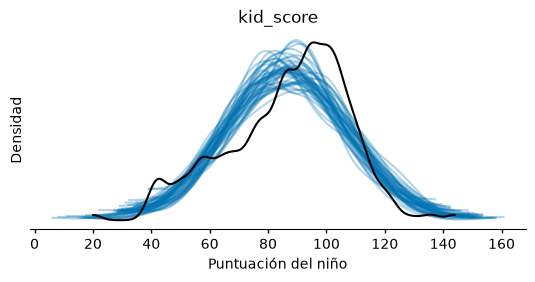

In [6]:
modelo_0.predict(idata_0, kind="response", random_seed=SEMILLA)
az.plot_ppc_dist(idata_0, var_names="kid_score", num_samples=50)
ax = plt.gcf().axes[0]
ax.set(xlabel="Puntuación del niño", ylabel="Densidad");

## Intercepto y pendiente comunes

Agregamos `mom_iq` a la fórmula.

In [7]:
modelo_1 = bmb.Model("kid_score ~ 1 + mom_iq", datos, family="gaussian")
modelo_1

       Formula: kid_score ~ 1 + mom_iq
        Family: gaussian
          Link: mu = identity
  Observations: 434
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 86.7972, sigma: 343.9751)
            mom_iq ~ Normal(mu: 0.0, sigma: 3.4018)
        
        Auxiliary parameters
            sigma ~ HalfStudentT(nu: 4.0, sigma: 20.3872)

In [8]:
idata_1 = modelo_1.fit(chains=4, random_seed=SEMILLA)

NUTS[nutpie]: [sigma, mom_iq, Intercept_centered]


Output()

In [9]:
az.summary(
    idata_1,
    var_names=["Intercept", "mom_iq", "sigma"],
    kind="all",
    ci_kind="eti",
    ci_prob=0.95,
    round_to=2
)

,mean,sd,eti95_lb,eti95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Intercept,25.83,5.94,14.38,37.79,6026.51,3120.18,1.0,0.08,0.10
mom_iq,0.61,0.06,0.49,0.72,6042.66,3142.56,1.0,0.00,0.00
sigma,18.29,0.61,17.19,19.51,6432.32,3234.47,1.0,0.01,0.01


`interpret.plot_predictions()` calcula y dibuja las predicciones sin armar las bandas a mano. Con `conditional="mom_iq"` evalúa una grilla de IQ. Por defecto muestra la media condicional. Pedimos intervalos del 50% y del 95% con `prob=[0.5, 0.95]`.

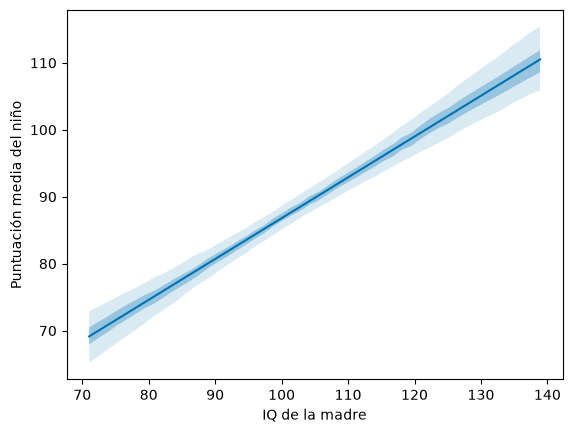

In [10]:
figura_1 = bmb.interpret.plot_predictions(
    modelo_1,
    idata_1,
    conditional="mom_iq",
    prob=[0.5, 0.95],
    fig_kwargs={"xlabel": "IQ de la madre", "ylabel": "Puntuación media del niño"},
)
figura_1

La función devuelve una figura de Matplotlib. Podemos reutilizarla para agregar los datos, cambiar el título y ajustar los límites.

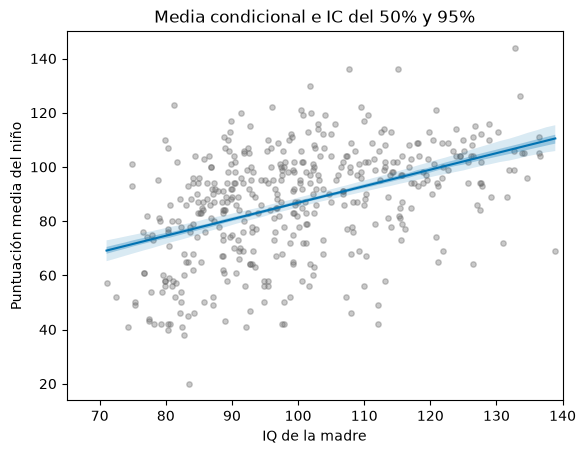

In [11]:
ax = figura_1.axes[0]
ax.scatter(datos["mom_iq"], datos["kid_score"], color="0.4", s=15, alpha=0.35, zorder=0)
ax.set(title="Media condicional e IC del 50% y 95%", xlim=(65, 140))
figura_1

Para obtener las bandas de un niño nuevo usamos `target="kid_score"`. Con `on=` podemos elegir dónde dibujar: acá reutilizamos los ejes de una figura con dos paneles para comparar la incertidumbre sobre la media y sobre una nueva puntuación.

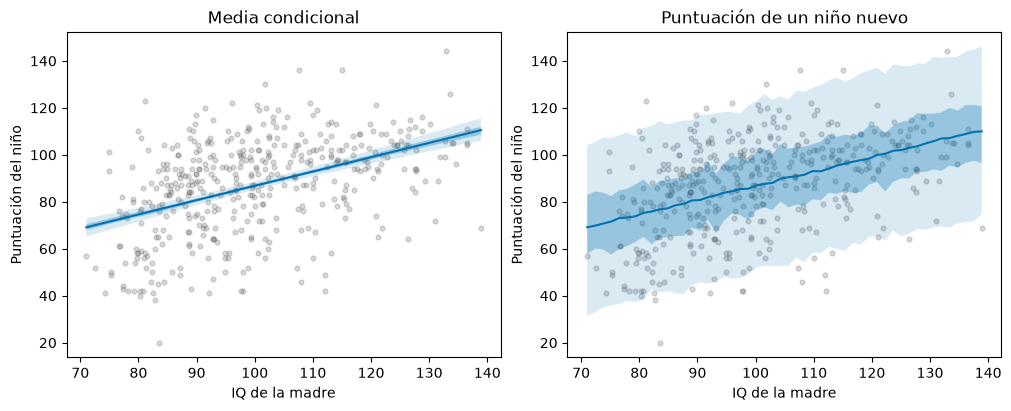

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True, layout="constrained")
targets = ["mean", "kid_score"]
titulos = ["Media condicional", "Puntuación de un niño nuevo"]
for ax, target, titulo in zip(axes, targets, titulos):
    bmb.interpret.plot_predictions(
        modelo_1,
        idata_1,
        conditional="mom_iq",
        target=target,
        prob=[0.5, 0.95],
        on=ax,
        fig_kwargs={"xlabel": "IQ de la madre", "ylabel": "Puntuación del niño"},
    )
    ax.scatter(datos["mom_iq"], datos["kid_score"], color="0.4", s=12, alpha=0.25, zorder=0)
    ax.set(title=titulo, xlabel="IQ de la madre", ylabel="Puntuación del niño")

Si queremos una tabla en lugar de un gráfico, usamos `interpret.predictions()`. Su atributo `.summary` ya trae las medias y los límites de los intervalos. Podemos cambiar la lista de IQ sin volver a ajustar.

In [13]:
iq_nuevos = [80.0, 100.0, 120.0]
preds_1 = bmb.interpret.predictions(
    modelo_1, idata_1, conditional={"mom_iq": iq_nuevos}, prob=[0.5, 0.95]
)
preds_1.summary

,mom_iq,estimate,lower_2.5%,upper_97.5%,lower_25.0%,upper_75.0%
0,80.0,74.602790,71.583675,77.458085,73.516662,75.467053
1,100.0,86.795503,85.124812,88.657468,86.330091,87.500055
2,120.0,98.988216,96.184882,101.840481,97.834522,99.820893


## Intercepto variable

`0 + mom_hs` crea un intercepto para cada grupo y `mom_iq` mantiene una pendiente común.

In [14]:
modelo_2 = bmb.Model("kid_score ~ 0 + mom_hs + mom_iq", datos, family="gaussian")
modelo_2

       Formula: kid_score ~ 0 + mom_hs + mom_iq
        Family: gaussian
          Link: mu = identity
  Observations: 434
        Priors: 
    target = mu
        Common-level effects
            mom_hs ~ Normal(mu: [0. 0.], sigma: [124.2132 124.2132])
            mom_iq ~ Normal(mu: 0.0, sigma: 3.4018)
        
        Auxiliary parameters
            sigma ~ HalfStudentT(nu: 4.0, sigma: 20.3872)

In [15]:
idata_2 = modelo_2.fit(chains=4, random_seed=SEMILLA)

NUTS[nutpie]: [sigma, mom_hs, mom_iq]


Output()

In [16]:
az.summary(idata_2, kind="all", ci_kind="eti", ci_prob=0.95, round_to=3)

,mean,sd,eti95_lb,eti95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mom_hs[No terminó],25.081,5.785,14.210,36.539,600.784,896.135,1.008,0.237,0.147
mom_hs[Terminó],31.063,6.181,19.446,42.927,584.715,791.627,1.009,0.257,0.160
mom_iq,0.570,0.060,0.455,0.683,574.201,798.489,1.009,0.002,0.002
sigma,18.192,0.626,17.034,19.489,2224.944,2163.380,1.003,0.013,0.012


Para ver cada grupo por separado, indicamos `panel="mom_hs"` en `subplot_kwargs`. Bambi calcula las bandas y arma los paneles.

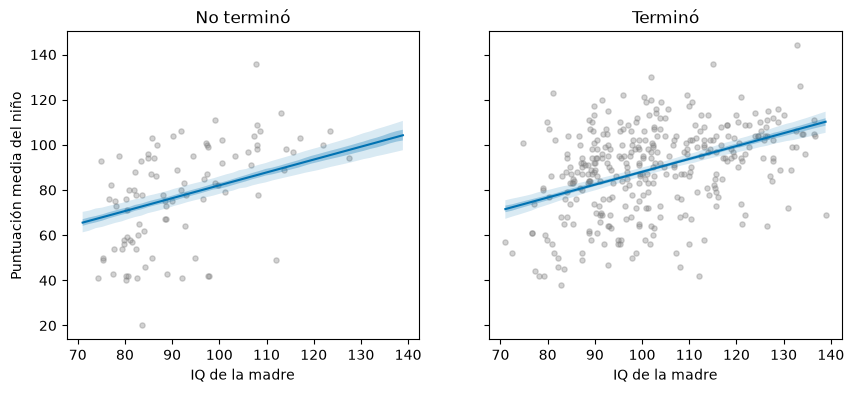

In [17]:
figura_2 = bmb.interpret.plot_predictions(
    modelo_2,
    idata_2,
    conditional=["mom_iq", "mom_hs"],
    prob=[0.5, 0.95],
    subplot_kwargs={"main": "mom_iq", "panel": "mom_hs"},
    fig_kwargs={
        "xlabel": "IQ de la madre",
        "ylabel": "Puntuación media del niño",
        "theme": {"figure.figsize": (10, 4)}
    },
)

for ax, grupo in zip(figura_2.axes, grupos):
    seleccion = datos["mom_hs"] == grupo
    ax.scatter(
        datos.loc[seleccion, "mom_iq"],
        datos.loc[seleccion, "kid_score"],
        color="0.5",
        s=14,
        alpha=0.35,
        zorder=0,
    )
    ax.set(title=grupo, xlabel="IQ de la madre", ylabel="Puntuación media del niño")

figura_2

## Intercepto y pendiente variables

Agregamos `mom_hs:mom_iq` para que las pendientes también puedan cambiar por grupo. Con esta fórmula, `mom_iq` es la pendiente del grupo de referencia y `mom_hs:mom_iq` representa el cambio de pendiente para el otro grupo.

In [18]:
modelo_3 = bmb.Model("kid_score ~ 0 + mom_hs + mom_iq + mom_hs:mom_iq", datos, family="gaussian")
modelo_3

       Formula: kid_score ~ 0 + mom_hs + mom_iq + mom_hs:mom_iq
        Family: gaussian
          Link: mu = identity
  Observations: 434
        Priors: 
    target = mu
        Common-level effects
            mom_hs ~ Normal(mu: [0. 0.], sigma: [124.2132 124.2132])
            mom_iq ~ Normal(mu: 0.0, sigma: 3.4018)
            mom_hs:mom_iq ~ Normal(mu: [0.], sigma: [1.1596])
        
        Auxiliary parameters
            sigma ~ HalfStudentT(nu: 4.0, sigma: 20.3872)

In [19]:
idata_3 = modelo_3.fit(chains=4, random_seed=SEMILLA)

NUTS[nutpie]: [sigma, mom_hs, mom_iq, mom_hs:mom_iq]


Output()

In [20]:
az.summary(idata_3, kind="all", ci_kind="eti", ci_prob=0.95, round_to=2)

,mean,sd,eti95_lb,eti95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mom_hs[No terminó],-10.74,13.96,-37.91,15.26,599.68,739.21,1.01,0.57,0.36
mom_hs[Terminó],39.32,6.67,26.32,52.11,1265.81,1356.21,1.00,0.19,0.14
mom_iq,0.96,0.15,0.68,1.25,604.09,740.91,1.01,0.01,0.00
mom_hs:mom_iq[Terminó],-0.47,0.16,-0.78,-0.15,650.95,793.48,1.01,0.01,0.00
sigma,18.00,0.61,16.83,19.25,3076.56,2481.64,1.00,0.01,0.01


También se puede escribir `kid_score ~ 1 + mom_hs + mom_iq + mom_hs:mom_iq`, o su abreviación `kid_score ~ mom_hs * mom_iq`. Con esas variantes, el intercepto corresponde al grupo de referencia y el coeficiente de `mom_hs` es una diferencia de interceptos. Las fórmulas representan las mismas rectas posibles, pero cambian la interpretación de los coeficientes. Al cambiar la parametrización también conviene revisar los _priors_.

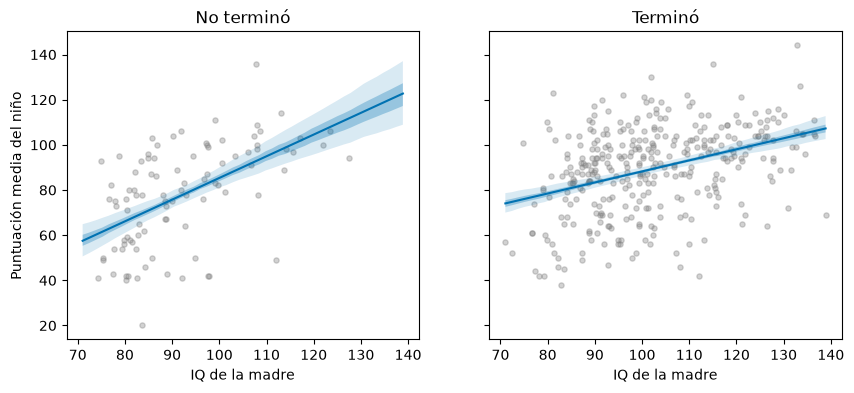

In [21]:
figura_3 = bmb.interpret.plot_predictions(
    modelo_3,
    idata_3,
    conditional=["mom_iq", "mom_hs"],
    prob=[0.5, 0.95],
    subplot_kwargs={"main": "mom_iq", "panel": "mom_hs"},
    fig_kwargs={
        "xlabel": "IQ de la madre",
        "ylabel": "Puntuación media del niño",
        "theme": {"figure.figsize": (10, 4)}
    },
)

for ax, grupo in zip(figura_3.axes, grupos):
    seleccion = datos["mom_hs"] == grupo
    ax.scatter(
        datos.loc[seleccion, "mom_iq"],
        datos.loc[seleccion, "kid_score"],
        color="0.5",
        s=14,
        alpha=0.35,
        zorder=0,
    )
    ax.set(title=grupo, xlabel="IQ de la madre", ylabel="Puntuación media del niño")

figura_3

Podemos obtener las predicciones para ambos grupos y varios IQ en una sola llamada.

In [22]:
preds_3 = bmb.interpret.predictions(
    modelo_3,
    idata_3,
    conditional={"mom_iq": iq_nuevos, "mom_hs": grupos},
    prob=[0.5, 0.95],
)
preds_3.summary

,mom_iq,mom_hs,estimate,lower_2.5%,upper_97.5%,lower_25.0%,upper_75.0%
0,80.0,No terminó,66.127008,61.022693,71.335988,64.634609,67.969115
1,80.0,Terminó,78.454597,75.286429,81.977593,77.161270,79.472729
2,100.0,No terminó,85.343639,81.138437,90.011277,83.941591,86.910844
3,100.0,Terminó,88.238521,86.343540,90.106343,87.485469,88.779218
4,120.0,No terminó,104.560270,95.716172,113.559386,101.314590,107.582965
5,120.0,Terminó,98.022446,95.162270,101.139445,96.994591,99.019474


Para comparar los grupos a igual IQ, `interpret.comparisons()` calcula directamente la diferencia entre sus medias. El orden del contraste indica que restamos «No terminó» a «Terminó».

In [23]:
diferencias_3 = bmb.interpret.comparisons(
    modelo_3,
    idata_3,
    contrast={"mom_hs": grupos},
    conditional={"mom_iq": iq_nuevos},
    prob=[0.5, 0.95],
)
diferencias_3.summary

,term,estimate_type,mom_iq,value,estimate,lower_2.5%,upper_97.5%,lower_25.0%,upper_75.0%
0,mom_hs,diff,80.0,No terminó_vs_Terminó,12.327589,6.433828,18.852589,10.221991,14.330348
1,mom_hs,diff,100.0,No terminó_vs_Terminó,2.894883,-1.978037,7.543556,1.058055,4.317987
2,mom_hs,diff,120.0,No terminó_vs_Terminó,-6.537824,-16.225071,2.534666,-10.127216,-3.641113


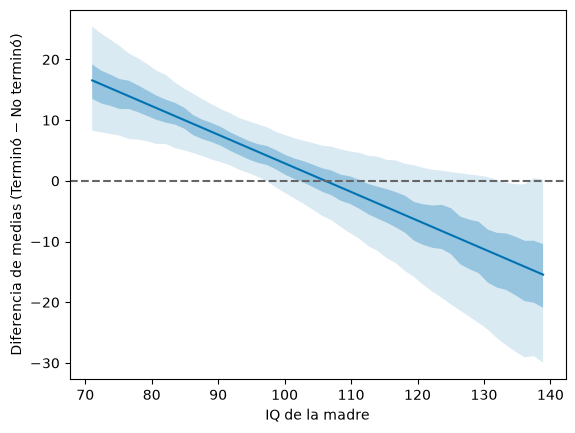

In [25]:
figura_diferencias = bmb.interpret.plot_comparisons(
    modelo_3,
    idata_3,
    contrast={"mom_hs": grupos},
    conditional="mom_iq",
    prob=[0.5, 0.95],
    fig_kwargs={
        "xlabel": "IQ de la madre",
        "ylabel": "Diferencia de medias (Terminó − No terminó)",
    },
)
figura_diferencias.axes[0].axhline(0, color="0.4", ls="--")
figura_diferencias

## Comparación de modelos

Primero generamos réplicas con las covariables observadas y comparamos sus distribuciones con las puntuaciones de los niños.

In [26]:
modelos = {
    "Sin covariables": modelo_0,
    "Intercepto y pendiente comunes": modelo_1,
    "Intercepto variable": modelo_2,
    "Intercepto y pendiente variables": modelo_3,
}
resultados = {
    "Sin covariables": idata_0,
    "Intercepto y pendiente comunes": idata_1,
    "Intercepto variable": idata_2,
    "Intercepto y pendiente variables": idata_3,
}

for nombre, modelo in modelos.items():
    modelo.predict(resultados[nombre], kind="response", random_seed=SEMILLA)

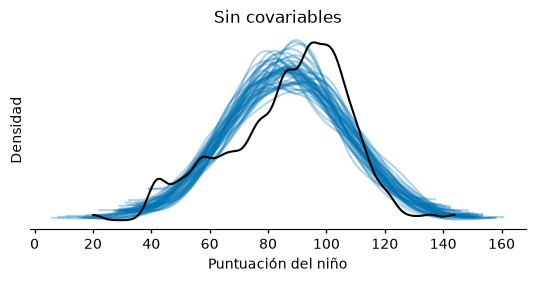

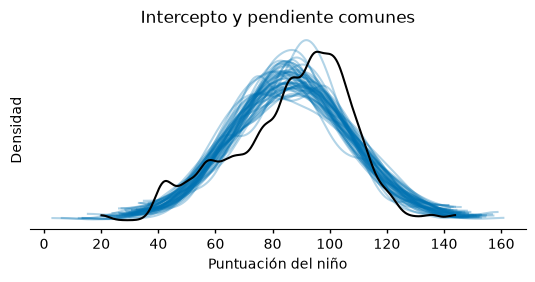

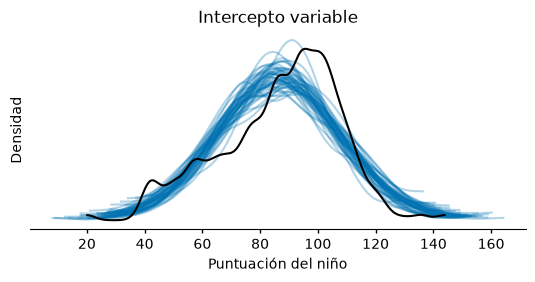

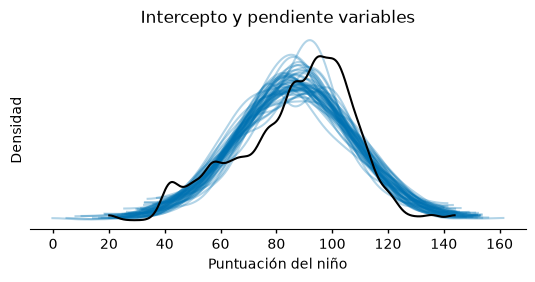

In [27]:
for nombre, idata in resultados.items():
    az.plot_ppc_dist(idata, var_names="kid_score", num_samples=50)
    ax = plt.gcf().axes[0]
    ax.set(title=nombre, xlabel="Puntuación del niño", ylabel="Densidad")

Para comparar la capacidad predictiva con LOO, agregamos las logverosimilitudes usando el método de Bambi y pasamos los resultados a ArviZ.

In [28]:
for nombre, modelo in modelos.items():
    modelo.compute_log_likelihood(resultados[nombre])

In [29]:
resultados_loo = {nombre: az.loo(idata, pointwise=True) for nombre, idata in resultados.items()}
comparacion = az.compare(resultados_loo, round_to=2)
comparacion

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Intercepto y pendiente variables,0,0.00,0.00,NaN,,,4.89,-1872.54,14.40,0.86
Intercepto variable,1,-3.55,2.81,0.90,|elpd_diff| < 4,,4.04,-1876.09,14.19,0.00
Intercepto y pendiente comunes,2,-6.04,4.11,0.93,,,2.92,-1878.58,14.51,0.14
Sin covariables,3,-53.77,9.90,1.00,,,1.97,-1926.31,14.16,0.00


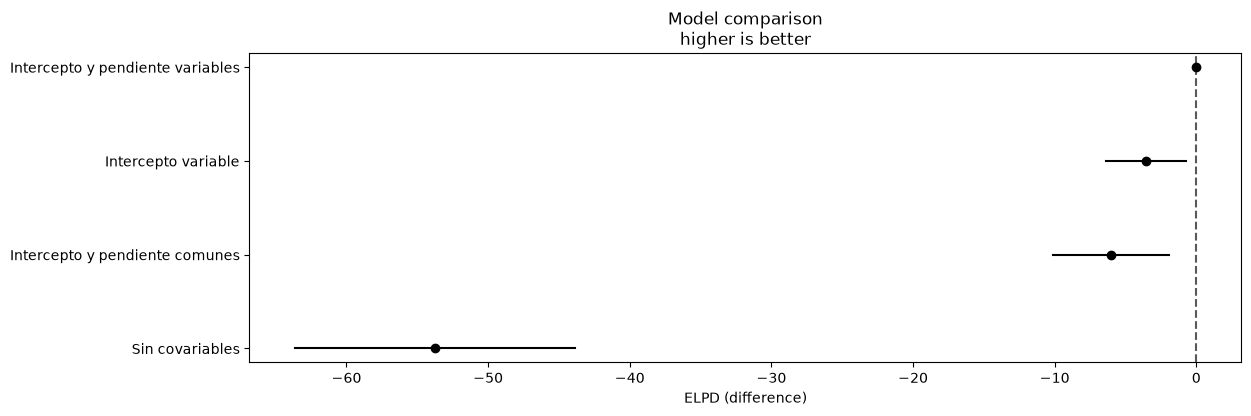

In [30]:
az.plot_compare(comparacion);

La tabla ordena los modelos por su capacidad predictiva estimada. Miramos `elpd_diff` junto con `dse` para evaluar el tamaño y la incertidumbre de las diferencias. Si aparecieran advertencias de Pareto $k$, revisamos esos casos antes de interpretar la comparación.